# 05. Temas de insatisfação nas avaliações negativas

**Universidade Presbiteriana Mackenzie** · Tecnologia em Banco de Dados · Projeto Aplicado II  
**Grupo Drop Table:** Igor Eduardo Dallan do Couto (RA 10748144), Jaqueline de Oliveira Alves (RA 10755023), Kayo Oliveira Nukui (RA 10356420) e Lucas de Lima Mendes (RA 10756562)  
**Empresa fictícia:** ConectaShop  
**Responsáveis por este notebook:** equipe Drop Table

O classificador dos notebooks 03 e 04 diz *se* o cliente está insatisfeito. Este notebook tenta responder *por quê*: quais assuntos aparecem com mais frequência nas avaliações com nota 1 e 2. Isso atende à Meta 2, que pede ao menos cinco temas recorrentes de insatisfação, identificados por análise de termos e modelagem de tópicos até a Etapa 3.

**Entrada:** `data/processed/avaliacoes_preparadas.csv` (só as avaliações negativas)

## 1. Método em uma frase

Usamos NMF (fatoração de matrizes não negativas): a tabela de pesos TF-IDF dos comentários é aproximada pelo produto de duas tabelas menores, **W** e **H**. Cada linha de **H** é um tópico, descrito pelos termos de maior peso; cada linha de **W** diz quanto de cada tópico existe em um comentário. Como nada pode ser negativo, cada comentário vira uma soma de "partes", o que facilita a leitura dos tópicos.

A NMF não diz o que cada tópico significa. Os nomes dos temas são dados por nós, depois de ler os termos e os comentários de maior peso em cada tópico.

### Bibliotecas utilizadas neste notebook

| Biblioteca | O que faz | Por que usamos neste notebook |
|---|---|---|
| `pandas` | Estrutura de dados em tabela (DataFrame) e leitura de CSV | Ler a base preparada e filtrar as avaliações negativas |
| `numpy` | Operações numéricas vetorizadas | Apoio numérico à leitura dos componentes da NMF |
| `matplotlib` | Biblioteca de gráficos de baixo nível | Gráfico do método do cotovelo e demais gráficos |
| `seaborn` | Gráficos estatísticos construídos sobre o matplotlib | Gráficos dos temas identificados |
| `scikit-learn` (`sklearn.cluster.KMeans`, `sklearn.decomposition.NMF`, `sklearn.feature_extraction.text.TfidfVectorizer`) | Biblioteca de aprendizado de máquina | Vetorização TF-IDF, teste do número de componentes (método do cotovelo) e extração dos temas por NMF |
| `nltk` | Kit de ferramentas de processamento de linguagem natural | Lista de stopwords em português, importada perto do trecho que a usa |

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Permite rodar o notebook a partir da pasta notebooks/ ou da raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

plt.style.use("seaborn-v0_8-whitegrid")

## 2. Avaliações negativas

In [10]:
caminho_dados = BASE_DIR / "data" / "processed" / "avaliacoes_preparadas.csv"
if not caminho_dados.exists():
    raise FileNotFoundError("Base preparada não encontrada. Rode o notebook 02 ou python -m src.preparacao.")

df_completo = pd.read_csv(caminho_dados)
df_negativos = df_completo[df_completo["sentimento"] == "negativo"].reset_index(drop=True)
print(f"Avaliações negativas (notas 1 e 2): {len(df_negativos):,}")

Avaliações negativas (notas 1 e 2): 10,245


Usamos a base preparada inteira (treino e teste juntos). Isso não interfere no classificador, porque esta análise é descritiva e não alimenta nenhum modelo supervisionado.

## 3. Vetorização para tópicos

Aqui o TF-IDF é diferente do usado na classificação. Removemos stopwords (lista do NLTK em português) e alguns termos que aparecem em quase toda reclamação e não indicam o motivo, como "produto", "compra" e "dia".

Um detalhe que afeta o resultado: este vetorizador não remove acentos, e a lista do NLTK contém "não" acentuado, mas não "nao". Por isso, "não" some da análise, enquanto "nao", escrito sem acento por muitos clientes, continua e aparece com peso alto em um dos tópicos.

In [11]:
import nltk
from nltk.corpus import stopwords

try:
    stopwords_pt = set(stopwords.words("portuguese"))
except LookupError:
    nltk.download("stopwords")
    stopwords_pt = set(stopwords.words("portuguese"))

stopwords_dominio = {
    "produto", "produtos", "compra", "compras", "comprei", "dia", "dias",
    "numero", "url", "email", "pois", "ainda", "ate", "agora", "ja", "so",
    "tudo", "nada", "muito", "pouco", "bem", "veio", "outro", "outra",
}

vetorizador_topicos = TfidfVectorizer(
    max_df=0.60,
    min_df=5,
    stop_words=list(stopwords_pt | stopwords_dominio),
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X_tfidf = vetorizador_topicos.fit_transform(df_negativos["texto_limpo"])
vocabulario = np.array(vetorizador_topicos.get_feature_names_out())
print(f"Matriz documento-termo: {X_tfidf.shape[0]:,} comentários x {X_tfidf.shape[1]:,} termos")

Matriz documento-termo: 10,245 comentários x 3,467 termos


## 4. Quantos tópicos?

A Meta 2 pede pelo menos cinco temas, então usamos cinco componentes. Para ver se os dados sugerem outro número, calculamos a inércia do k-Means (soma das distâncias de cada comentário ao centro do seu grupo) para k de 2 a 7. Se houvesse um "cotovelo", um ponto a partir do qual a inércia para de cair rápido, ele indicaria um número natural de grupos.

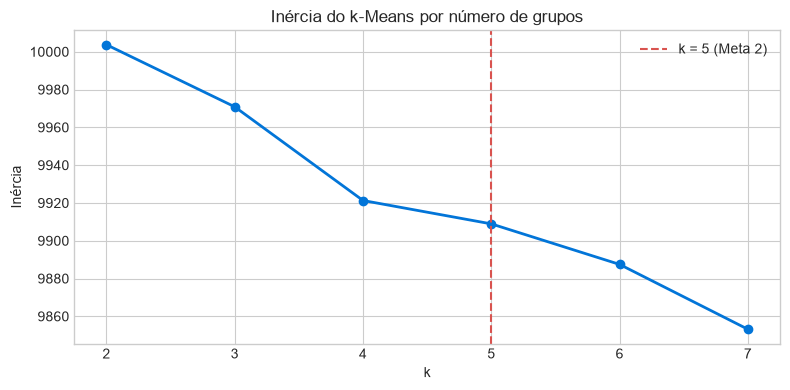

Queda total da inércia de k=2 a k=7: 1.5%


In [12]:
k_candidatos = range(2, 8)
inercias = [KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_tfidf).inertia_ for k in k_candidatos]

plt.figure(figsize=(8, 4))
plt.plot(list(k_candidatos), inercias, "o-", color="#0275d8", lw=2)
plt.axvline(5, color="#d9534f", linestyle="--", label="k = 5 (Meta 2)")
plt.title("Inércia do k-Means por número de grupos")
plt.xlabel("k")
plt.ylabel("Inércia")
plt.legend()
plt.tight_layout()
plt.show()

queda = (inercias[0] - inercias[-1]) / inercias[0]
print(f"Queda total da inércia de k=2 a k=7: {queda:.1%}")

**Leitura.** A inércia cai pouco em todo o intervalo e não há cotovelo claro. Os comentários não formam grupos bem separados, o que é comum em textos curtos. O número cinco vem da meta, e não dos dados.

## 5. Tópicos encontrados pela NMF

Mostramos os 15 termos de maior peso de cada componente. Neste ponto os componentes ainda não têm nome.

In [13]:
nmf = NMF(n_components=5, random_state=42, max_iter=500, init="nndsvd")
W = nmf.fit_transform(X_tfidf)
H = nmf.components_

for i, pesos in enumerate(H, 1):
    termos = vocabulario[np.argsort(pesos)[::-1][:15]]
    print(f"Componente {i}: {', '.join(termos)}\n")

Componente 1: recebi, apenas, recebi apenas, dois, paguei, recebi recebi, nao recebi, momento, pedido, momento recebi, recebi mercadoria, duas, hoje, mercadoria, errado

Componente 2: chegou, nao chegou, dois, pedido, nota, chegou chegou, apenas, fiscal, nota fiscal, quero, esperando, chegou prazo, mercadoria, defeito, quebrado

Componente 3: nao, nao recebi, nao chegou, nao entregue, nao recomendo, recomendo, recebi nao, gostei, nao gostei, qualidade, momento nao, entrega nao, entregue nao, loja, nao posso

Componente 4: entregue, pedido, momento, pedido entregue, nao entregue, consta, entregue entregue, apenas, dois, entregue prazo, entregue momento, site, somente, entregue recebi, momento entregue

Componente 5: entrega, prazo, prazo entrega, demora, passou, loja, atraso, aguardando, passou prazo, demora entrega, recomendo, hoje, entrega recebi, data, lannister



## 6. Quantos comentários caem em cada componente

Cada comentário é atribuído ao componente de maior peso em **W**. É uma simplificação: um comentário pode falar de mais de um assunto.

In [14]:
df_negativos["componente"] = W.argmax(axis=1) + 1
sem_peso = int((W.max(axis=1) == 0).sum())

distribuicao = pd.DataFrame({
    "comentarios": df_negativos["componente"].value_counts().sort_index(),
    "proporcao_%": (df_negativos["componente"].value_counts(normalize=True).sort_index() * 100).round(2),
})
display(distribuicao)
print(f"Comentários com peso zero em todos os componentes (atribuídos ao componente 1 pela regra do maior peso): {sem_peso}")

,comentarios,proporcao_%
componente,,
1,1995,19.47
2,1744,17.02
3,760,7.42
4,1738,16.96
5,4008,39.12


Comentários com peso zero em todos os componentes (atribuídos ao componente 1 pela regra do maior peso): 48


## 7. Comentários de maior peso em cada componente

Para dar nome a um tópico, lemos os comentários em que ele tem mais peso.

In [15]:
for i in range(5):
    print(f"=== Componente {i + 1} ===")
    for idx in np.argsort(-W[:, i])[:6]:
        print("  *", df_negativos.loc[idx, "texto_original"][:110])
    print()

=== Componente 1 ===
  * Não recebi o produto liquid koolbloom
  * Não recebi nada até agora
  * Só recebi as máscaras, não recebi as luvas.
  * Faturou e não recebi!
  * Ainda não recebi este produto,
  * Ainda nã recebi o produto

=== Componente 2 ===
  * Não chegou o produto
  * ñ chegou o produto
  * Não chegou nada do meu produto.
  * Não chegou. Nada a declarar.
  * Comprei o espeto flex e o estinho flex.
o Espeto flex giratório não chegou ainda.
  * O produto não chegou ainda

=== Componente 3 ===
  * nao e pontual nao recebi meu produto
  * nao rercebi ainda
  * os produtos ainda nao foram entrgues
  * Ainda nao rrecebi
  * Ainda nao recevi o produto.
  * Nao recebei o produto até agora.

=== Componente 4 ===
  * Meu produto não foi entregue.
  * produto n foi entregue
  * Comprei o produto há 40 dias e ainda não foi entregue.
  * Esse produto não foi entregue
  * Ainda não foi entregue
  * Meu produto não foi entregue ainda

=== Componente 5 ===
  * Prazo de entrega
  * Ñ comp

## 8. Leitura dos componentes

| Componente | Termos que se destacam | O que os comentários mostram | Tema |
|---|---|---|---|
| 1 | recebi, apenas, recebi apenas, dois, paguei, errado | Pedido que não chegou, chegou pela metade ou com item trocado | Não recebimento ou recebimento incompleto |
| 2 | chegou, nao chegou, pedido, nota fiscal, esperando | Produto que ainda não chegou ou chegou só em parte | Não recebimento ou recebimento incompleto |
| 3 | nao, nao recebi, nao recomendo, nao gostei, qualidade | Comentários escritos sem acento, a maioria sobre não recebimento e alguns sobre qualidade | Misto, agrupado pela palavra "nao" |
| 4 | entregue, nao entregue, consta, pedido entregue | Pedido que ainda não foi entregue | Não recebimento ou recebimento incompleto |
| 5 | entrega, prazo, demora, atraso, aguardando | Reclamação de prazo vencido e demora | Atraso na entrega |

**O que isso significa para a Meta 2.** Os cinco componentes não correspondem a cinco motivos diferentes. Três deles (1, 2 e 4) falam do mesmo problema, o produto que não chegou ou chegou incompleto, e se separam principalmente pelo verbo usado ("recebi", "chegou", "entregue"). O componente 3 junta comentários pela palavra "nao" escrita sem acento, um efeito do pré-processamento, e mistura não recebimento com queixas de qualidade. Defeito, produto diferente do anunciado e dificuldade de cancelamento ou estorno aparecem em comentários, mas não formam tópicos próprios. Com a configuração atual, os dados sustentam de forma clara dois temas: **não recebimento ou recebimento incompleto** e **atraso na entrega**. A Meta 2 fica, portanto, parcialmente demonstrada; o prazo dela é a Etapa 3.

,comentarios,proporcao_%
tema,,
Não recebimento / incompleto,5477,53.46
Atraso na entrega,4008,39.12
Misto (palavra 'nao'),760,7.42


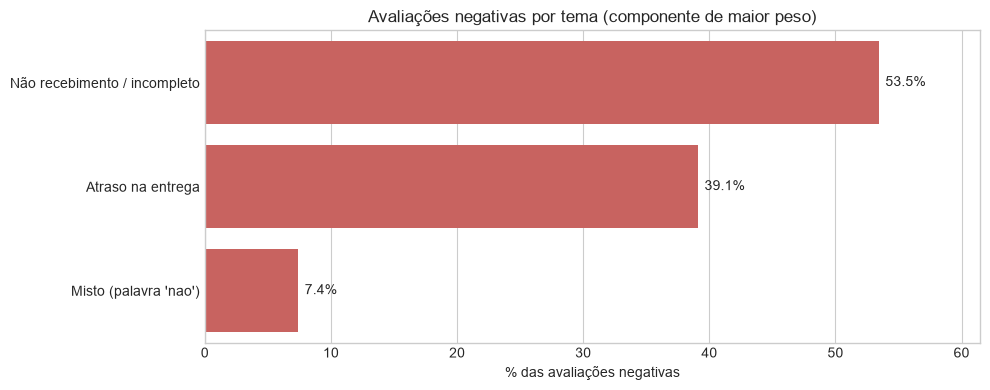

In [16]:
temas = {
    1: "Não recebimento / incompleto",
    2: "Não recebimento / incompleto",
    3: "Misto (palavra 'nao')",
    4: "Não recebimento / incompleto",
    5: "Atraso na entrega",
}
df_negativos["tema"] = df_negativos["componente"].map(temas)

por_tema = (df_negativos["tema"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"comentarios": df_negativos["tema"].value_counts(), "proporcao_%": por_tema}))

plt.figure(figsize=(10, 4))
sns.barplot(x=por_tema.values, y=por_tema.index, color="#d9534f")
for i, v in enumerate(por_tema.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.title("Avaliações negativas por tema (componente de maior peso)")
plt.xlabel("% das avaliações negativas")
plt.ylabel("")
plt.xlim(0, por_tema.max() + 8)
plt.tight_layout()
plt.show()

## 9. O que dá para recomendar

A partir dos dois temas consolidados pela modelagem de tópicos dos comentários negativos, a ConectaShop pode direcionar ações práticas de pós-venda e atendimento utilizando a própria classificação de sentimentos gerada pelo modelo:

1. **Triagem prioritária de não recebimento (53,5% das queixas):** Encaminhar automaticamente para a fila crítica do SAC as avaliações com termos associados a produto não recebido ou incompleto, agilizando a verificação e o reenvio de volumes.
2. **Canal proativo para queixas de atraso (39,1% das queixas):** Utilizar a detecção textual de insatisfação com prazos para priorizar o contato com o cliente e abrir chamados diretos de acareação logística.

## 10. Próximos passos (Etapa 3)

- Tratar acentos antes de aplicar as stopwords, para que "não" e "nao" recebam o mesmo tratamento.
- Repetir a NMF com outras sementes e comparar os termos, para verificar se os tópicos são estáveis.
- Dar nome aos temas só depois de ler uma amostra de comentários, com revisão de mais de um integrante.

Qualquer ajuste deve ser julgado pela clareza e estabilidade dos temas, e não pelo número de rótulos. Se os dados sustentarem menos de cinco temas distintos, esse é o resultado a relatar.